# E-commerce Business Analytics Using Python

### Project Overview
This project analyzes the Brazilian Olist E-commerce dataset to understand sales performance, customer behavior, product categories, payment methods, delivery performance, and customer satisfaction.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("E-commerce Business Analytics Project")
print("Libraries imported successfully!")

E-commerce Business Analytics Project
Libraries imported successfully!


## 2. Loading Datasets

In [2]:
# Load the Olist Customers Dataset

customers = pd.read_csv("../Dataset/olist_customers_dataset.csv")

# Display first 5 rows
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


## 3. Data Exploration

In [3]:
customers.shape

(99441, 5)

In [4]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


## 4. Data Cleaning

In [5]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [6]:
customers.duplicated().sum()

np.int64(0)

In [7]:
customers.nunique()

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64

In [8]:
customers.describe(include='all')

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [9]:
customers['customer_city'].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

## 5. Exploratory Data Analysis (EDA)

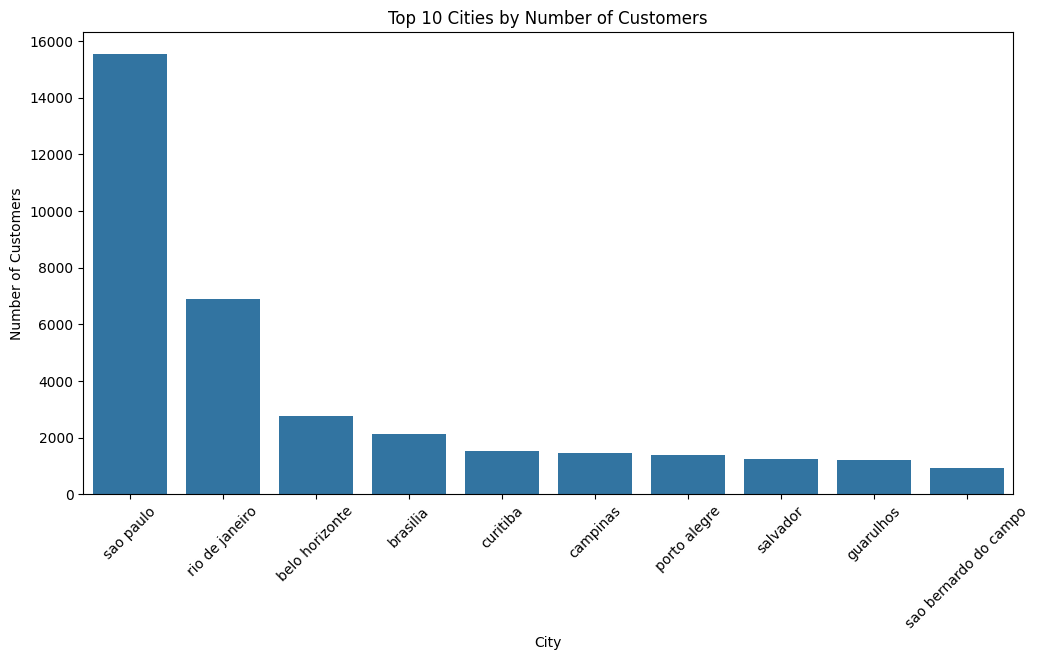

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

top_cities = customers['customer_city'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(x=top_cities.index, y=top_cities.values)

plt.title('Top 10 Cities by Number of Customers')
plt.xlabel('City')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

In [11]:
orders = pd.read_csv("../Dataset/olist_orders_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [12]:
orders.shape

(99441, 8)

In [13]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [14]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [15]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

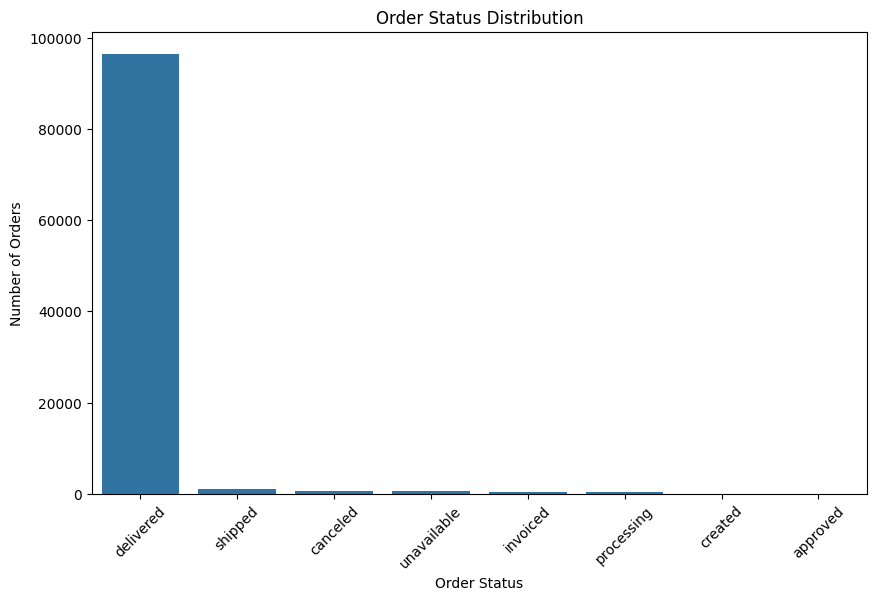

In [16]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=orders,
    x='order_status',
    order=orders['order_status'].value_counts().index
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.savefig("../Visualizations/order_status_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

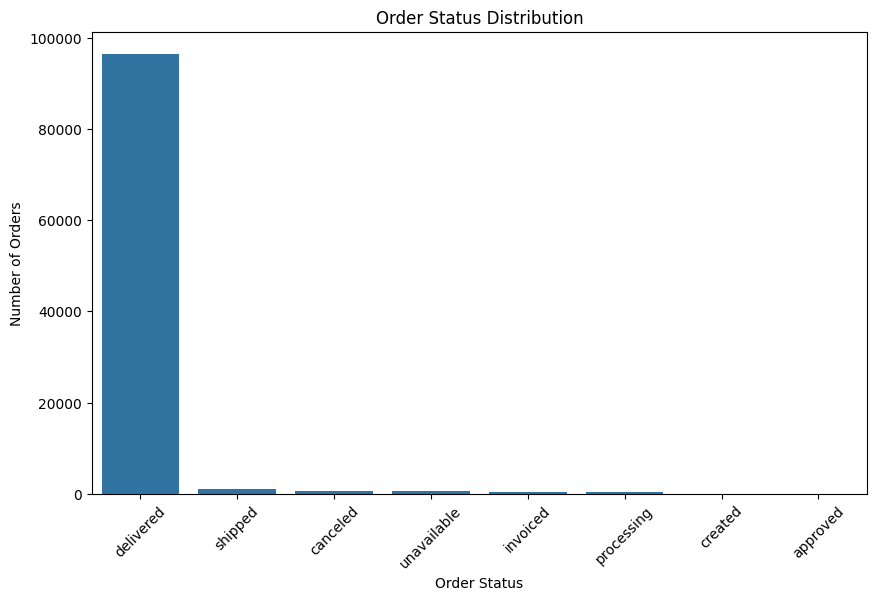

In [17]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=orders,
    x='order_status',
    order=orders['order_status'].value_counts().index
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

In [18]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

orders['order_purchase_timestamp'].head()

0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[ns]

In [19]:
orders['order_year'] = orders['order_purchase_timestamp'].dt.year

orders['order_year'].value_counts().sort_index()

order_year
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

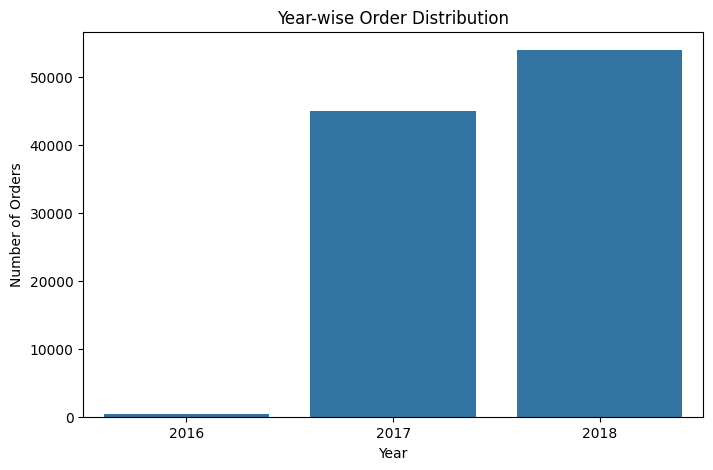

In [20]:
yearly_orders = orders['order_year'].value_counts().sort_index()

plt.figure(figsize=(8,5))
sns.barplot(x=yearly_orders.index, y=yearly_orders.values)

plt.title('Year-wise Order Distribution')
plt.xlabel('Year')
plt.ylabel('Number of Orders')

plt.show()

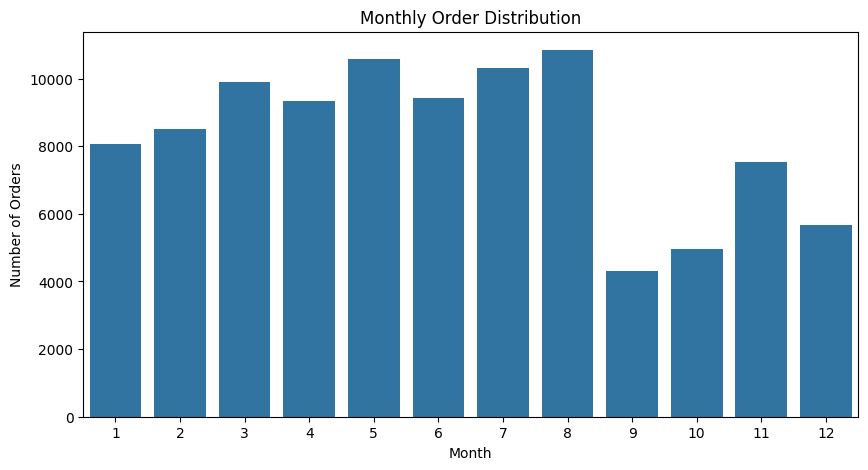

In [21]:
orders['order_month'] = orders['order_purchase_timestamp'].dt.month

monthly_orders = orders['order_month'].value_counts().sort_index()

plt.figure(figsize=(10,5))
sns.barplot(x=monthly_orders.index, y=monthly_orders.values)

plt.title('Monthly Order Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.show()

In [22]:
orders['month_name'] = orders['order_purchase_timestamp'].dt.strftime('%B')

monthly_trend = orders['month_name'].value_counts()

monthly_trend

month_name
August       10843
May          10573
July         10318
March         9893
June          9412
April         9343
February      8508
January       8069
November      7544
December      5674
October       4959
September     4305
Name: count, dtype: int64

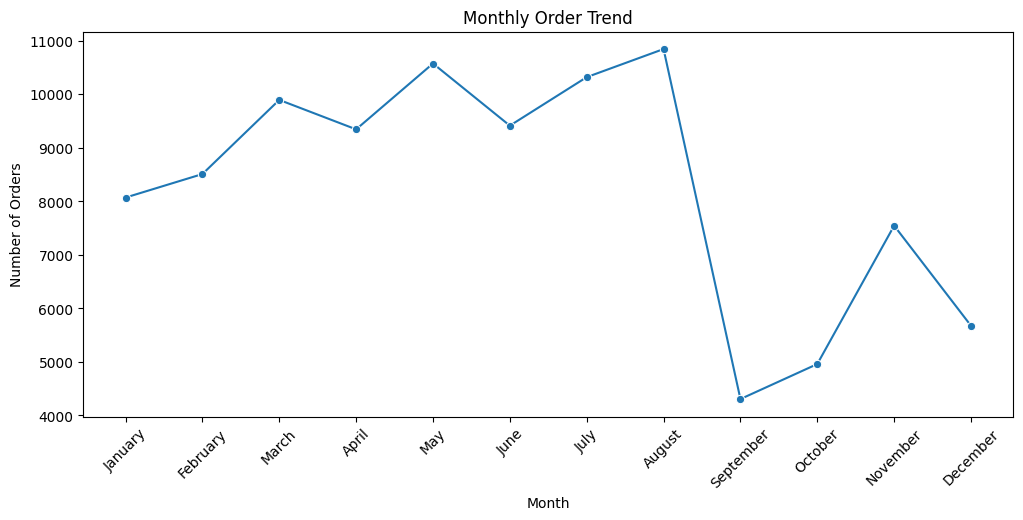

In [23]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_trend = orders['month_name'].value_counts().reindex(month_order)

plt.figure(figsize=(12,5))
sns.lineplot(x=monthly_trend.index, y=monthly_trend.values, marker='o')

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

In [24]:
orders['order_year_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

yearly_monthly_orders = orders.groupby(
    ['order_year', 'month_name']
).size().reset_index(name='order_count')

yearly_monthly_orders.head(15)

,order_year,month_name,order_count
0,2016,December,1
1,2016,October,324
2,2016,September,4
3,2017,April,2404
4,2017,August,4331
5,2017,December,5673
6,2017,February,1780
7,2017,January,800
8,2017,July,4026
9,2017,June,3245


In [25]:
monthly_comparison = orders.pivot_table(
    index='order_month',
    columns='order_year',
    values='order_id',
    aggfunc='count',
    fill_value=0
)

monthly_comparison.index = month_order
monthly_comparison

order_year,2016,2017,2018
January,0,800,7269
February,0,1780,6728
March,0,2682,7211
April,0,2404,6939
May,0,3700,6873
June,0,3245,6167
July,0,4026,6292
August,0,4331,6512
September,4,4285,16
October,324,4631,4


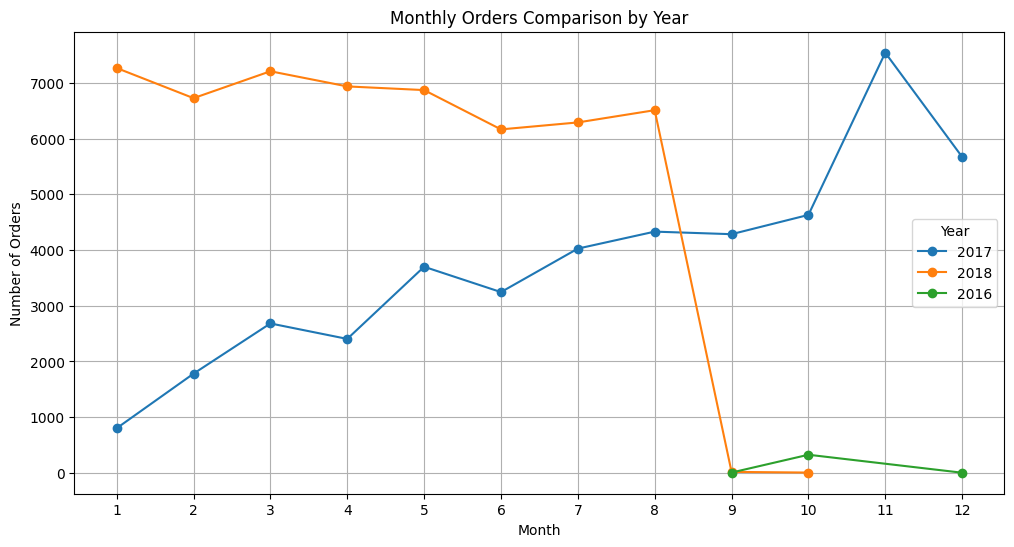

In [26]:
plt.figure(figsize=(12,6))

for year in orders['order_year'].unique():
    yearly_data = orders[orders['order_year'] == year]
    monthly_data = yearly_data.groupby('order_month')['order_id'].count()

    plt.plot(monthly_data.index, monthly_data.values, marker='o', label=year)

plt.title('Monthly Orders Comparison by Year')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1,13))
plt.legend(title='Year')
plt.grid(True)

plt.show()

In [27]:
orders['order_delivered_customer_date'] = pd.to_datetime(
    orders['order_delivered_customer_date']
)

orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

orders['delivery_time'] = (
    orders['order_delivered_customer_date'] -
    orders['order_purchase_timestamp']
).dt.days

orders['delivery_time'].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time, dtype: float64

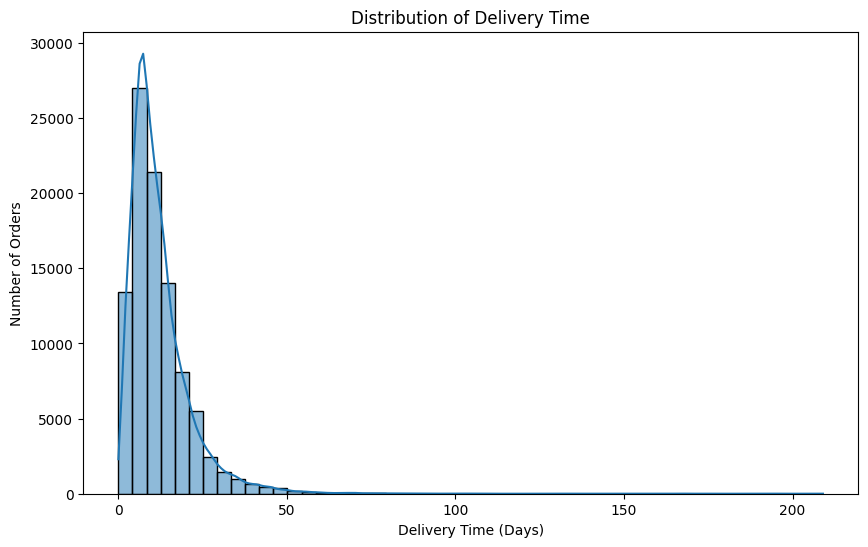

In [28]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=orders,
    x='delivery_time',
    bins=50,
    kde=True
)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (Days)')
plt.ylabel('Number of Orders')

plt.show()

In [29]:
delivered_orders = orders[
    orders['order_status'] == 'delivered'
]

delivered_orders.groupby('order_status')['delivery_time'].mean()

order_status
delivered    12.093604
Name: delivery_time, dtype: float64

In [30]:
orders['order_estimated_delivery_date'] = pd.to_datetime(
    orders['order_estimated_delivery_date']
)

delivered_orders = orders[
    orders['order_status'] == 'delivered'
].copy()

delivered_orders['delivery_difference'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_estimated_delivery_date']
).dt.days

delivered_orders['delivery_difference'].describe()

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delivery_difference, dtype: float64

In [31]:
early_deliveries = (
    delivered_orders['delivery_difference'] < 0
).sum()

late_deliveries = (
    delivered_orders['delivery_difference'] > 0
).sum()

on_time_deliveries = (
    delivered_orders['delivery_difference'] == 0
).sum()

print("Early Deliveries:", early_deliveries)
print("Late Deliveries:", late_deliveries)
print("On-time Deliveries:", on_time_deliveries)

Early Deliveries: 88644
Late Deliveries: 6534
On-time Deliveries: 1292


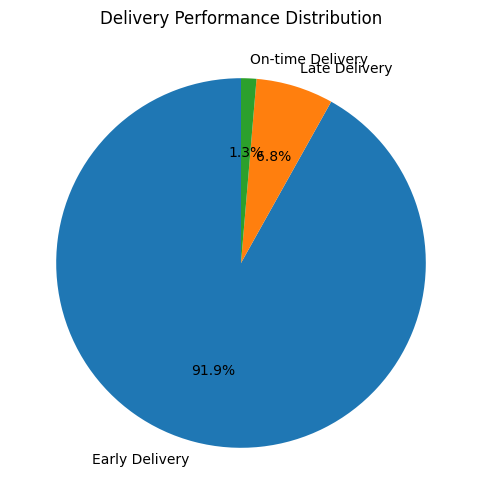

In [32]:
delivery_counts = pd.Series({
    'Early Delivery': early_deliveries,
    'Late Delivery': late_deliveries,
    'On-time Delivery': on_time_deliveries
})

plt.figure(figsize=(9,6))

plt.pie(
    delivery_counts,
    labels=delivery_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Delivery Performance Distribution')
plt.show()

In [33]:
late_orders = delivered_orders[
    delivered_orders['delivery_difference'] > 0
].copy()

late_orders['delivery_difference'].describe()

count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: delivery_difference, dtype: float64

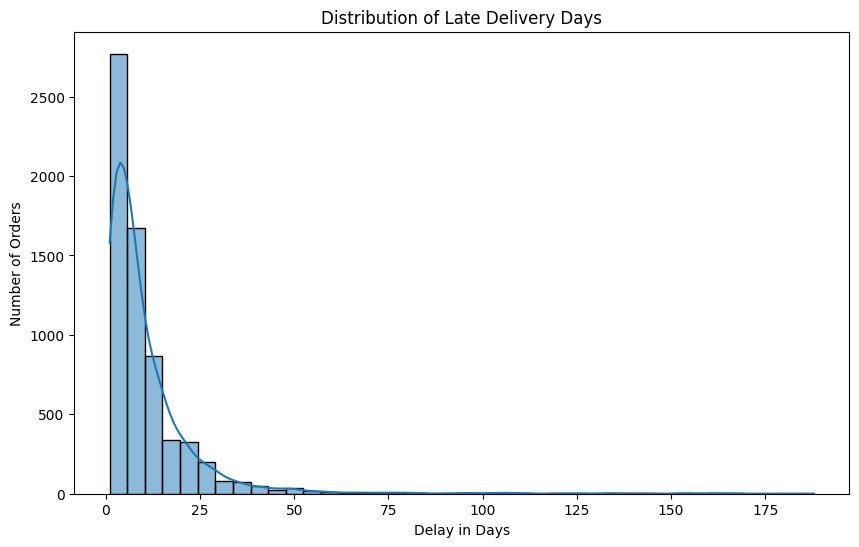

In [34]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=late_orders,
    x='delivery_difference',
    bins=40,
    kde=True
)

plt.title('Distribution of Late Delivery Days')
plt.xlabel('Delay in Days')
plt.ylabel('Number of Orders')

plt.show()

In [35]:
orders['order_approved_at'] = pd.to_datetime(
    orders['order_approved_at']
)

orders['approval_time'] = (
    orders['order_approved_at'] -
    orders['order_purchase_timestamp']
).dt.total_seconds() / 3600

orders['approval_time'].describe()

count    99281.000000
mean        10.419094
std         26.038004
min          0.000000
25%          0.215000
50%          0.343333
75%         14.580833
max       4509.180556
Name: approval_time, dtype: float64

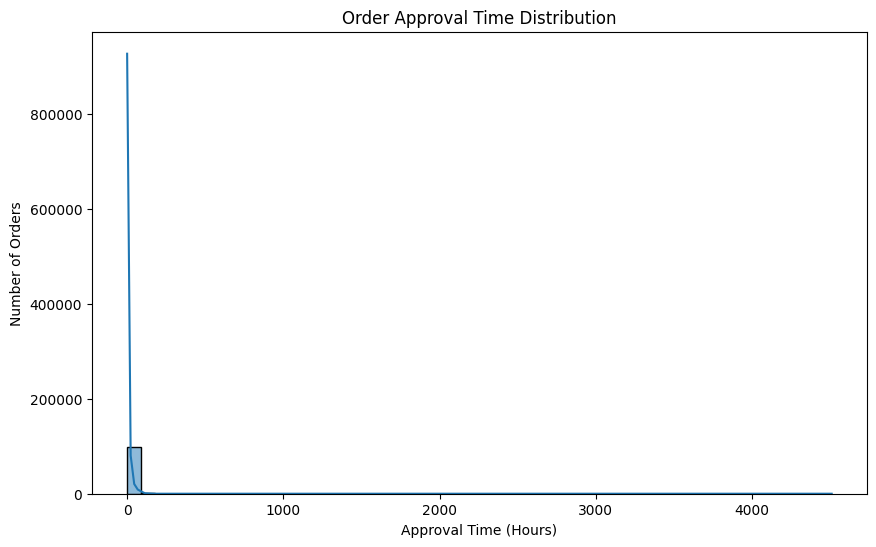

In [36]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=orders,
    x='approval_time',
    bins=50,
    kde=True
)

plt.title('Order Approval Time Distribution')
plt.xlabel('Approval Time (Hours)')
plt.ylabel('Number of Orders')

plt.show()

In [37]:
orders['order_delivered_carrier_date'] = pd.to_datetime(
    orders['order_delivered_carrier_date']
)

orders['processing_time'] = (
    orders['order_delivered_carrier_date'] -
    orders['order_approved_at']
).dt.total_seconds() / 3600

orders['processing_time'].describe()

count    97644.000000
mean        67.320916
std         85.186249
min      -4109.256111
25%         21.012222
50%         43.641528
75%         85.931250
max       3018.301667
Name: processing_time, dtype: float64

In [38]:
negative_processing = orders[
    orders['processing_time'] < 0
]

negative_processing[
    [
        'order_id',
        'order_approved_at',
        'order_delivered_carrier_date',
        'processing_time'
    ]
].head(10)

,order_id,order_approved_at,order_delivered_carrier_date,processing_time
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-12 23:31:02,2018-06-11 14:54:00,-32.617222
64,688052146432ef8253587b930b01a06d,2018-04-24 18:25:22,2018-04-23 19:19:14,-23.102222
199,58d4c4747ee059eeeb865b349b41f53a,2018-07-26 23:31:53,2018-07-24 12:57:00,-58.581389
210,412fccb2b44a99b36714bca3fef8ad7b,2018-07-23 12:31:53,2018-07-23 12:24:00,-0.131389
415,56a4ac10a4a8f2ba7693523bb439eede,2018-07-27 23:31:09,2018-07-24 14:03:00,-81.469167
481,32e4fa9bb468884309b58b9348de70c3,2018-07-05 16:33:06,2018-07-05 14:50:00,-1.718333
483,4df92d82d79c3b52c7138679fa9b07fc,2018-07-29 23:30:52,2018-07-26 14:46:00,-80.747778
585,16e38caa92e342c7780f68832f832d4d,2018-05-07 16:52:39,2018-05-07 15:09:00,-1.727500
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 14:05:13,2018-08-16 13:27:00,-0.636944
817,6051e6d3da9a50b7325cbe9c81025062,2018-07-05 16:31:26,2018-07-04 12:14:00,-28.290556


In [39]:
negative_processing_count = (
    orders['processing_time'] < 0
).sum()

print("Negative Processing Records:", negative_processing_count)

Negative Processing Records: 1359


In [40]:
valid_processing = orders[
    orders['processing_time'] >= 0
].copy()

valid_processing['processing_time'].describe()

count    96285.000000
mean        68.620465
std         83.965777
min          0.004167
25%         21.636944
50%         44.440000
75%         86.977222
max       3018.301667
Name: processing_time, dtype: float64

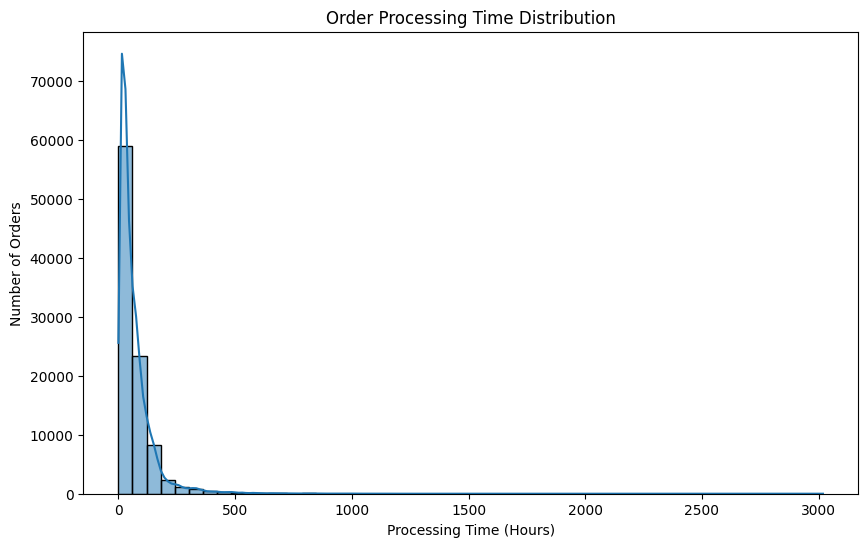

In [41]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=valid_processing,
    x='processing_time',
    bins=50,
    kde=True
)

plt.title('Order Processing Time Distribution')
plt.xlabel('Processing Time (Hours)')
plt.ylabel('Number of Orders')

plt.show()

In [42]:
valid_processing.groupby('order_year')['processing_time'].mean()

order_year
2016    317.982694
2017     72.812267
2018     63.750985
Name: processing_time, dtype: float64

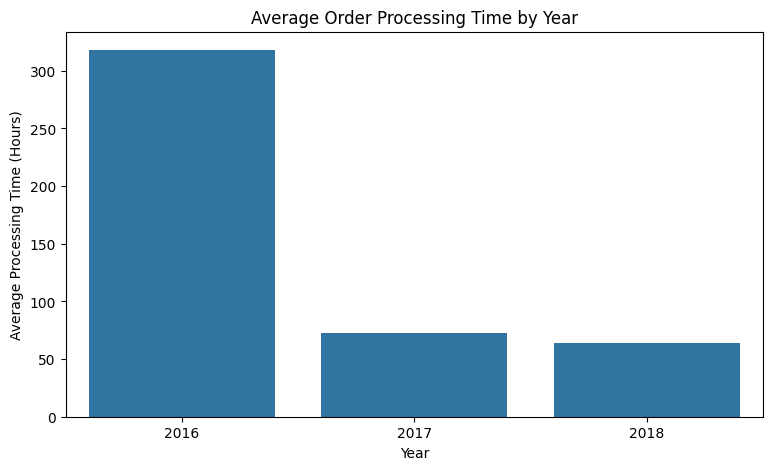

In [43]:
yearly_processing = valid_processing.groupby(
    'order_year'
)['processing_time'].mean()

plt.figure(figsize=(9,5))

sns.barplot(
    x=yearly_processing.index,
    y=yearly_processing.values
)

plt.title('Average Order Processing Time by Year')
plt.xlabel('Year')
plt.ylabel('Average Processing Time (Hours)')

plt.show()

In [44]:
delivered_orders.groupby('order_year')['delivery_time'].mean()

order_year
2016    19.209738
2017    12.541335
2018    11.689202
Name: delivery_time, dtype: float64

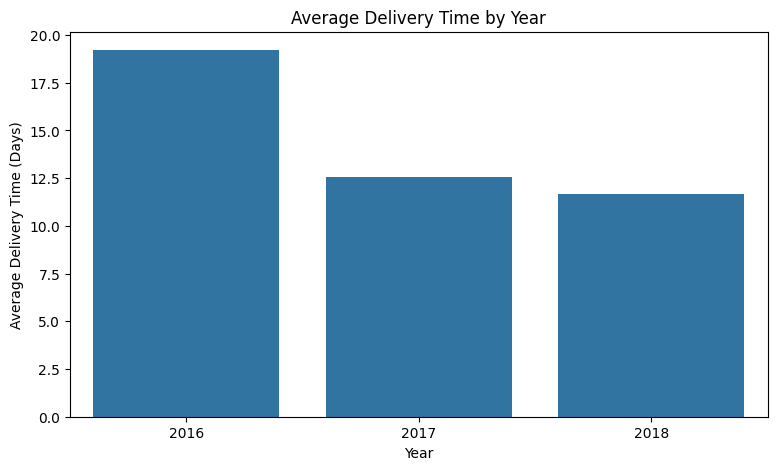

In [45]:
yearly_delivery = delivered_orders.groupby(
    'order_year'
)['delivery_time'].mean()

plt.figure(figsize=(9,5))

sns.barplot(
    x=yearly_delivery.index,
    y=yearly_delivery.values
)

plt.title('Average Delivery Time by Year')
plt.xlabel('Year')
plt.ylabel('Average Delivery Time (Days)')

plt.show()

In [46]:
order_items = pd.read_csv(
    "../Dataset/olist_order_items_dataset.csv"
)

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [47]:
order_items.shape

(112650, 7)

In [48]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [49]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [50]:
order_items.duplicated().sum()

np.int64(0)

In [51]:
order_items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [52]:
total_revenue = order_items['price'].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 13591643.7


In [53]:
total_shipping = order_items['freight_value'].sum()

print("Total Shipping Cost:", total_shipping)

Total Shipping Cost: 2251909.54


In [54]:
total_orders = order_items['order_id'].nunique()

print("Total Unique Orders:", total_orders)

Total Unique Orders: 98666


In [55]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", average_order_value)

Average Order Value: 137.75407637889444


In [56]:
top_products = order_items['product_id'].value_counts().head(10)

top_products

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: count, dtype: int64

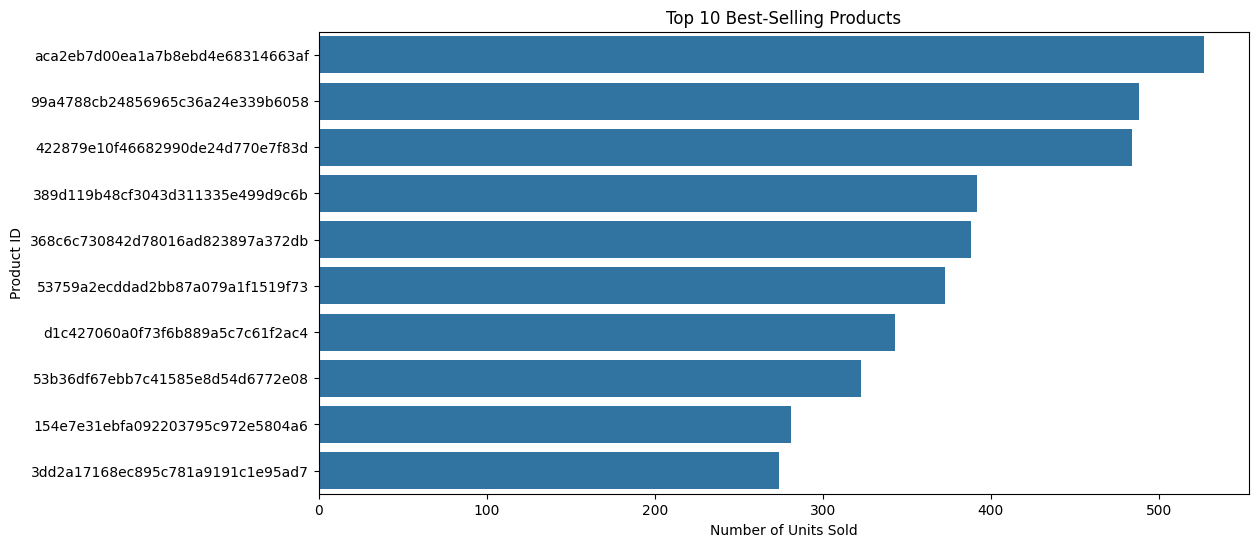

In [57]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Number of Units Sold')
plt.ylabel('Product ID')
plt.savefig("../Visualizations/top_10_best_selling_products.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [58]:
top_revenue_products = (
    order_items.groupby('product_id')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_revenue_products

product_id
bb50f2e236e5eea0100680137654686c    63885.00
6cdd53843498f92890544667809f1595    54730.20
d6160fb7873f184099d9bc95e30376af    48899.34
d1c427060a0f73f6b889a5c7c61f2ac4    47214.51
99a4788cb24856965c36a24e339b6058    43025.56
3dd2a17168ec895c781a9191c1e95ad7    41082.60
25c38557cf793876c5abdd5931f922db    38907.32
5f504b3a1c75b73d6151be81eb05bdc9    37733.90
53b36df67ebb7c41585e8d54d6772e08    37683.42
aca2eb7d00ea1a7b8ebd4e68314663af    37608.90
Name: price, dtype: float64

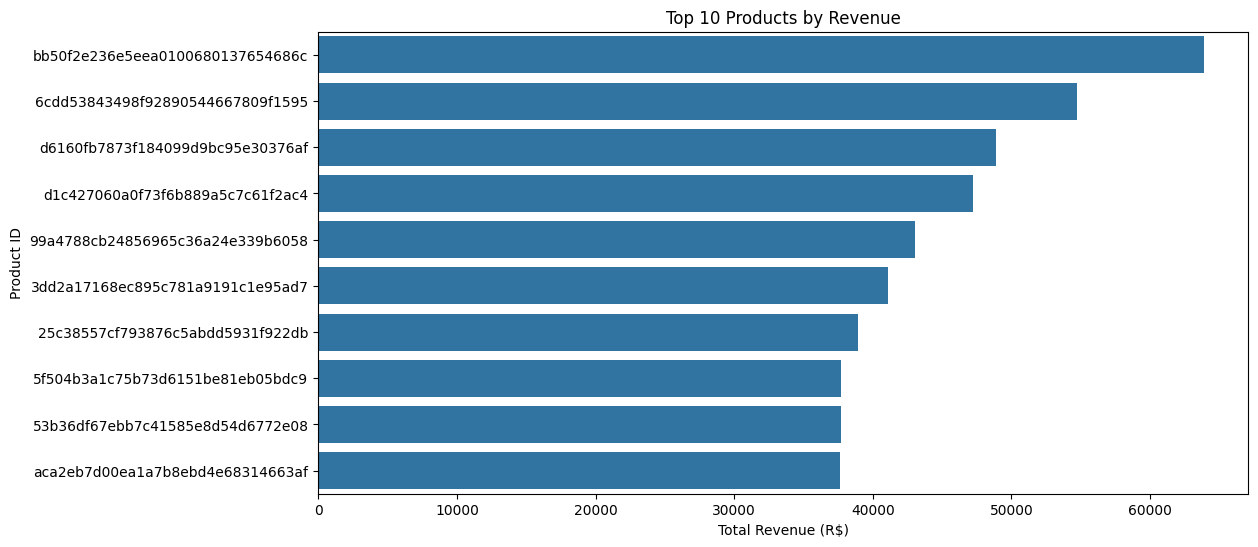

In [59]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_revenue_products.values,
    y=top_revenue_products.index
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue (R$)')
plt.ylabel('Product ID')
plt.show()

In [60]:
items_per_order = order_items.groupby('order_id')['order_item_id'].count()

items_per_order.describe()

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: order_item_id, dtype: float64

In [61]:
items_per_order.value_counts().sort_index()

order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [62]:
single_item_orders = (items_per_order == 1).sum()
multiple_item_orders = (items_per_order > 1).sum()

print("Single Item Orders:", single_item_orders)
print("Multiple Item Orders:", multiple_item_orders)

print("Single Item Percentage:", 
      round(single_item_orders / len(items_per_order) * 100, 2))

print("Multiple Item Percentage:", 
      round(multiple_item_orders / len(items_per_order) * 100, 2))

Single Item Orders: 88863
Multiple Item Orders: 9803
Single Item Percentage: 90.06
Multiple Item Percentage: 9.94


In [63]:
payments = pd.read_csv("../Dataset/olist_order_payments_dataset.csv")

payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [64]:
payments.shape

(103886, 5)

In [65]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [66]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [67]:
payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

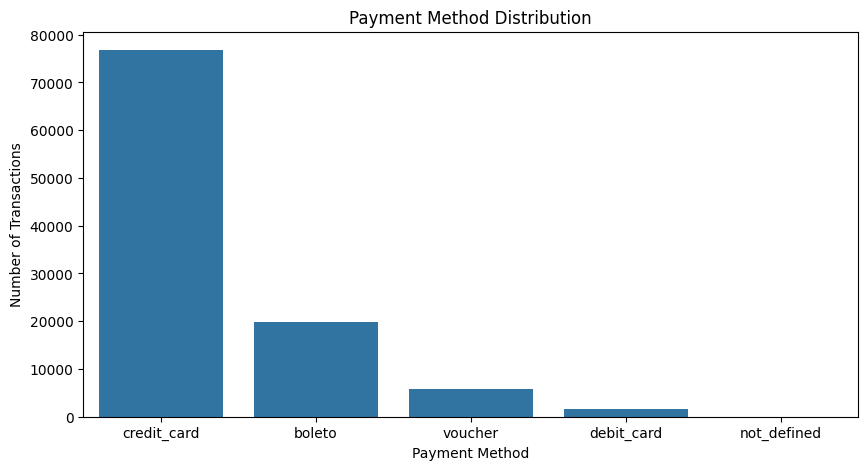

In [68]:
payment_counts = payments['payment_type'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=payment_counts.index, y=payment_counts.values)

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.show()

In [69]:
payments['payment_installments'].describe()

count    103886.000000
mean          2.853349
std           2.687051
min           0.000000
25%           1.000000
50%           1.000000
75%           4.000000
max          24.000000
Name: payment_installments, dtype: float64

In [70]:
payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

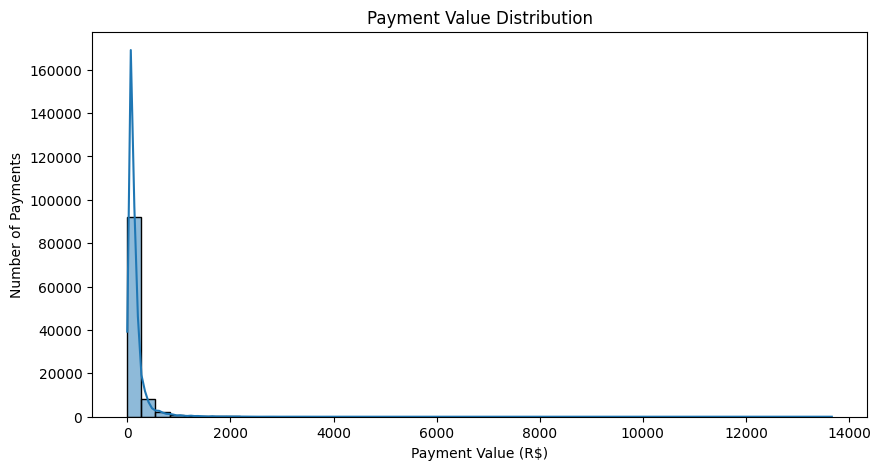

In [71]:
plt.figure(figsize=(10, 5))

sns.histplot(payments['payment_value'], bins=50, kde=True)

plt.title('Payment Value Distribution')
plt.xlabel('Payment Value (R$)')
plt.ylabel('Number of Payments')

plt.show()

In [72]:
payment_revenue = payments.groupby('payment_type')['payment_value'].sum().sort_values(ascending=False)

payment_revenue

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64

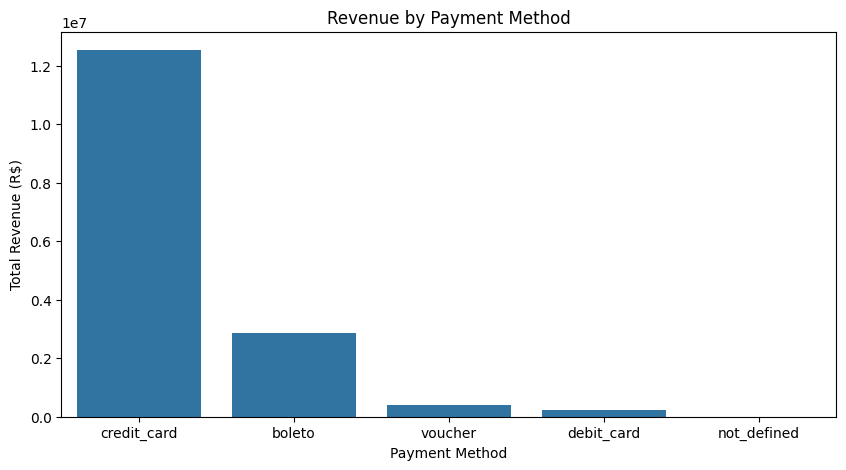

In [73]:
plt.figure(figsize=(10, 5))

sns.barplot(x=payment_revenue.index, y=payment_revenue.values)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue (R$)')

plt.show()

In [74]:
products = pd.read_csv("../Dataset/olist_products_dataset.csv")

products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [75]:
products.shape

(32951, 9)

In [76]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [77]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [78]:
products['product_category_name'].value_counts().head(10)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

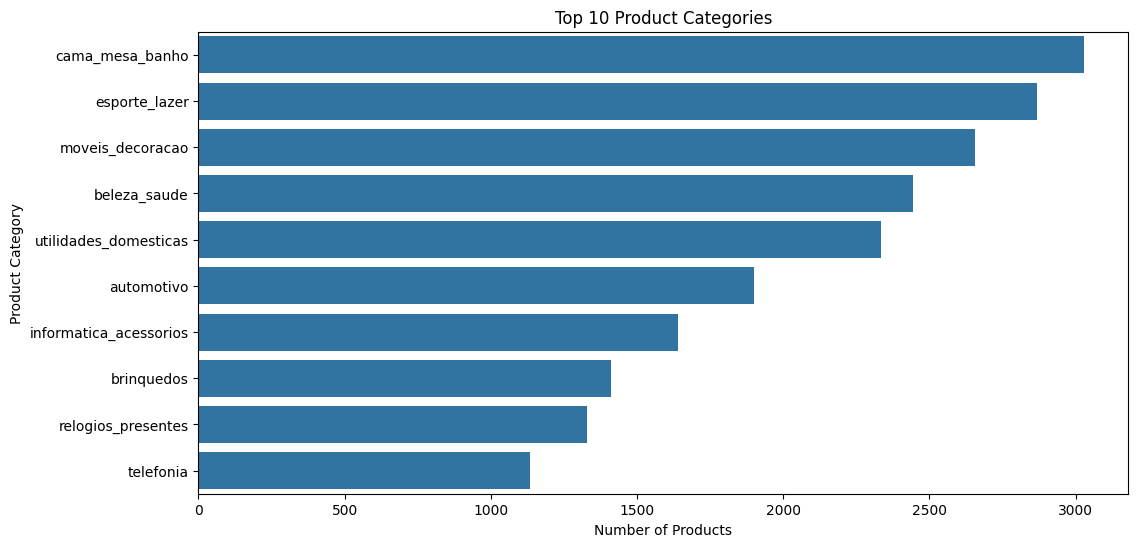

In [79]:
top_categories = products['product_category_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title('Top 10 Product Categories')
plt.xlabel('Number of Products')
plt.ylabel('Product Category')

plt.show()

In [80]:
products['product_weight_g'].describe()

count    32949.000000
mean      2276.472488
std       4282.038731
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

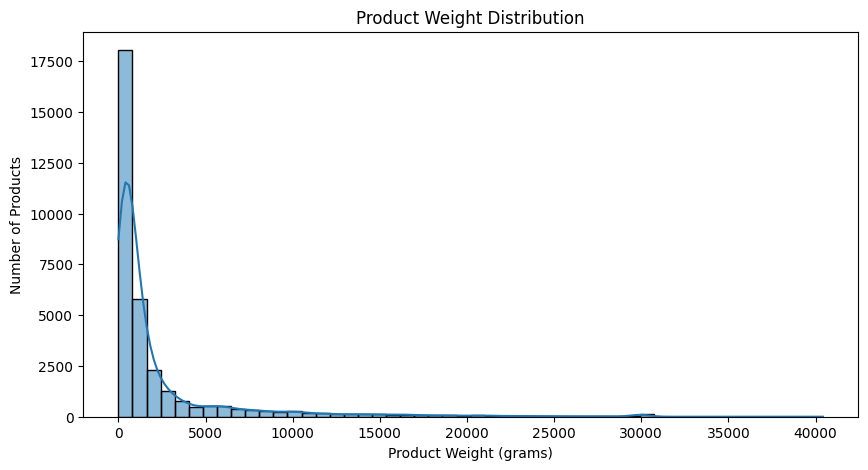

In [81]:
plt.figure(figsize=(10, 5))

sns.histplot(products['product_weight_g'].dropna(), bins=50, kde=True)

plt.title('Product Weight Distribution')
plt.xlabel('Product Weight (grams)')
plt.ylabel('Number of Products')

plt.show()

In [82]:

products[['product_length_cm', 'product_height_cm', 'product_width_cm']].describe()

,product_length_cm,product_height_cm,product_width_cm
count,32949.000000,32949.000000,32949.000000
mean,30.815078,16.937661,23.196728
std,16.914458,13.637554,12.079047
min,7.000000,2.000000,6.000000
25%,18.000000,8.000000,15.000000
50%,25.000000,13.000000,20.000000
75%,38.000000,21.000000,30.000000
max,105.000000,105.000000,118.000000


In [83]:
products['product_category_name'].nunique()

73

In [84]:
sellers = pd.read_csv("../Dataset/olist_sellers_dataset.csv")

sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [85]:
sellers.shape

(3095, 4)

In [86]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [87]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [88]:
top_seller_cities = sellers['seller_city'].value_counts().head(10)

top_seller_cities

seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
guarulhos          50
ibitinga           49
santo andre        45
campinas           41
maringa            40
Name: count, dtype: int64

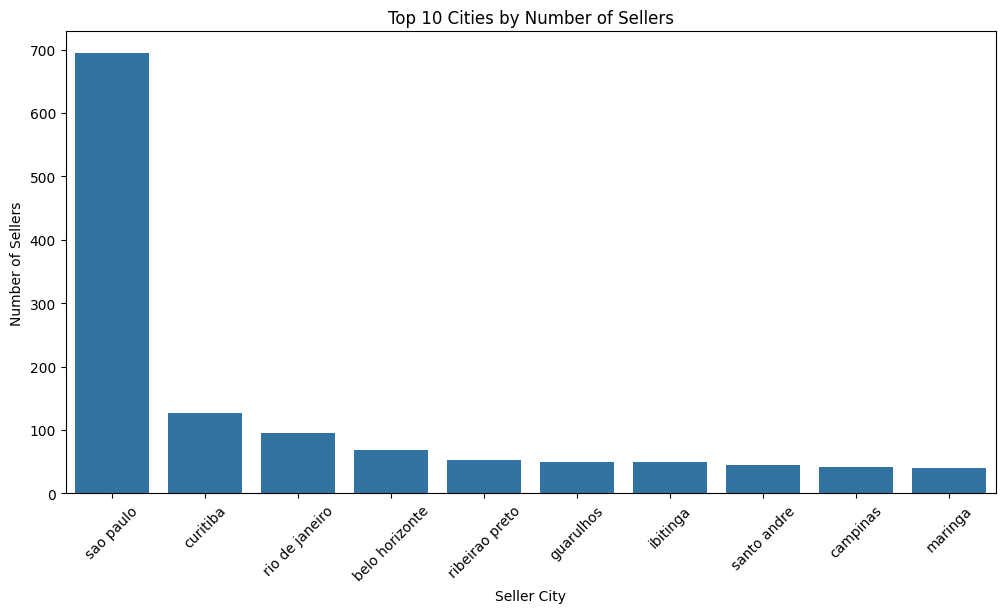

In [89]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=top_seller_cities.index,
    y=top_seller_cities.values
)

plt.title('Top 10 Cities by Number of Sellers')
plt.xlabel('Seller City')
plt.ylabel('Number of Sellers')
plt.xticks(rotation=45)
plt.show()

In [90]:
sellers['seller_state'].value_counts().head(10)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

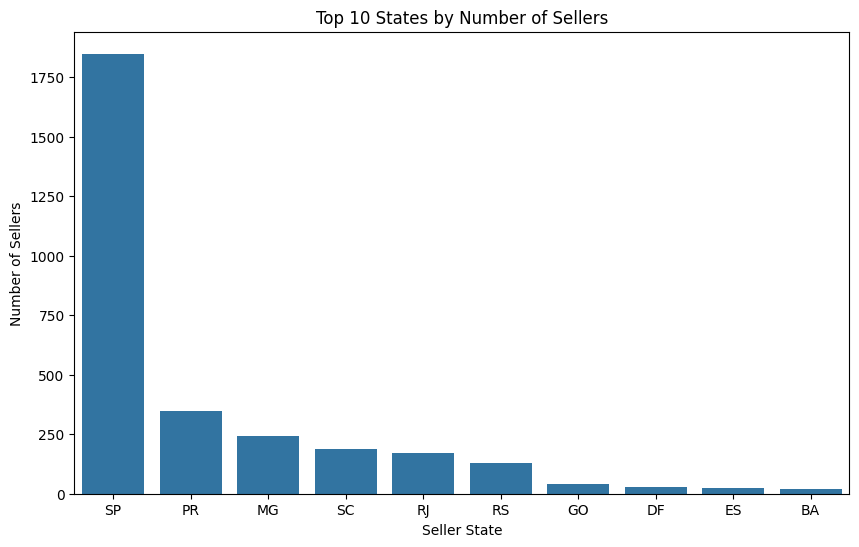

In [91]:
top_seller_states = sellers['seller_state'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_seller_states.index,
    y=top_seller_states.values
)

plt.title('Top 10 States by Number of Sellers')
plt.xlabel('Seller State')
plt.ylabel('Number of Sellers')
plt.show()

In [92]:
print("Total Sellers:", sellers['seller_id'].nunique())

print("Unique Seller Cities:", sellers['seller_city'].nunique())

print("Unique Seller States:", sellers['seller_state'].nunique())


Total Sellers: 3095
Unique Seller Cities: 611
Unique Seller States: 23


In [93]:
reviews = pd.read_csv("../Dataset/olist_order_reviews_dataset.csv")

reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [94]:
reviews.shape

(99224, 7)

In [95]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [96]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [97]:
reviews['review_score'].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

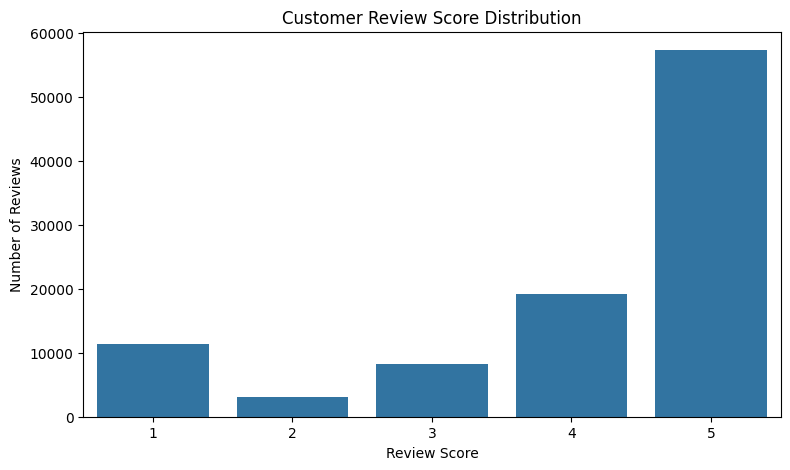

In [98]:
review_counts = reviews['review_score'].value_counts().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(x=review_counts.index, y=review_counts.values)
plt.title('Customer Review Score Distribution')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.savefig("../Visualizations/customer_review_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [99]:
average_rating = reviews['review_score'].mean()

print("Average Customer Rating:", round(average_rating, 2))

Average Customer Rating: 4.09


In [100]:
positive = (reviews['review_score'] >= 4).sum()
neutral = (reviews['review_score'] == 3).sum()
negative = (reviews['review_score'] <= 2).sum()

print("Positive Reviews:", positive)
print("Neutral Reviews:", neutral)
print("Negative Reviews:", negative)

Positive Reviews: 76470
Neutral Reviews: 8179
Negative Reviews: 14575


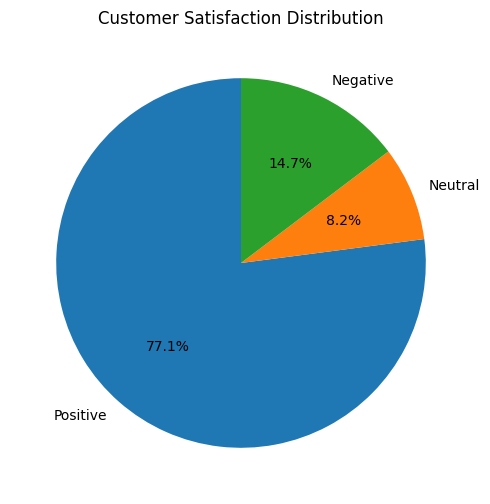

In [101]:
review_summary = pd.Series({
    'Positive': positive,
    'Neutral': neutral,
    'Negative': negative
})

plt.figure(figsize=(8, 6))
plt.pie(
    review_summary,
    labels=review_summary.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Satisfaction Distribution')
plt.show()

In [102]:
review_orders = reviews.merge(
    orders[['order_id', 'delivery_time']],
    on='order_id',
    how='inner'
)

review_orders[['review_score', 'delivery_time']].head()

,review_score,delivery_time
0,4,6.0
1,5,9.0
2,5,13.0
3,5,10.0
4,5,18.0


In [103]:
review_delivery = review_orders.groupby('review_score')['delivery_time'].mean()

print(review_delivery)

review_score
1    20.849825
2    16.194832
3    13.795278
4    11.848054
5    10.224097
Name: delivery_time, dtype: float64


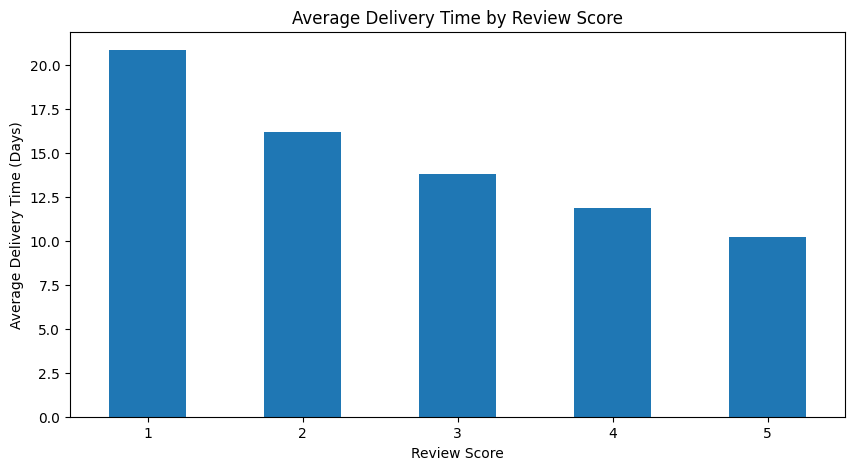

In [104]:
plt.figure(figsize=(10, 5))

review_delivery.plot(kind='bar')

plt.title('Average Delivery Time by Review Score')
plt.xlabel('Review Score')
plt.ylabel('Average Delivery Time (Days)')
plt.xticks(rotation=0)
plt.savefig("../Visualizations/average_delivery_by_review_score.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [105]:
category_translation = pd.read_csv(
    "../Dataset/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [106]:
products = products.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

products[['product_category_name', 'product_category_name_english']].head(10)

,product_category_name,product_category_name_english
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares
5,instrumentos_musicais,musical_instruments
6,cool_stuff,cool_stuff
7,moveis_decoracao,furniture_decor
8,eletrodomesticos,home_appliances
9,brinquedos,toys


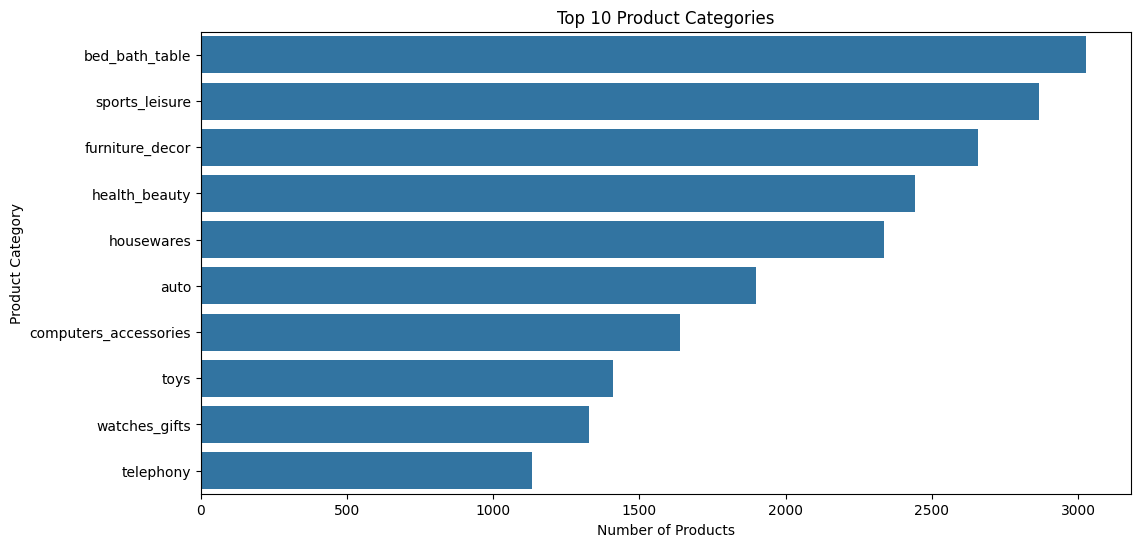

In [107]:
top_categories = products['product_category_name_english'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title('Top 10 Product Categories')
plt.xlabel('Number of Products')
plt.ylabel('Product Category')
plt.savefig("../Visualizations/top_10_product_categories.png",
            dpi=300, bbox_inches="tight")
plt.show()

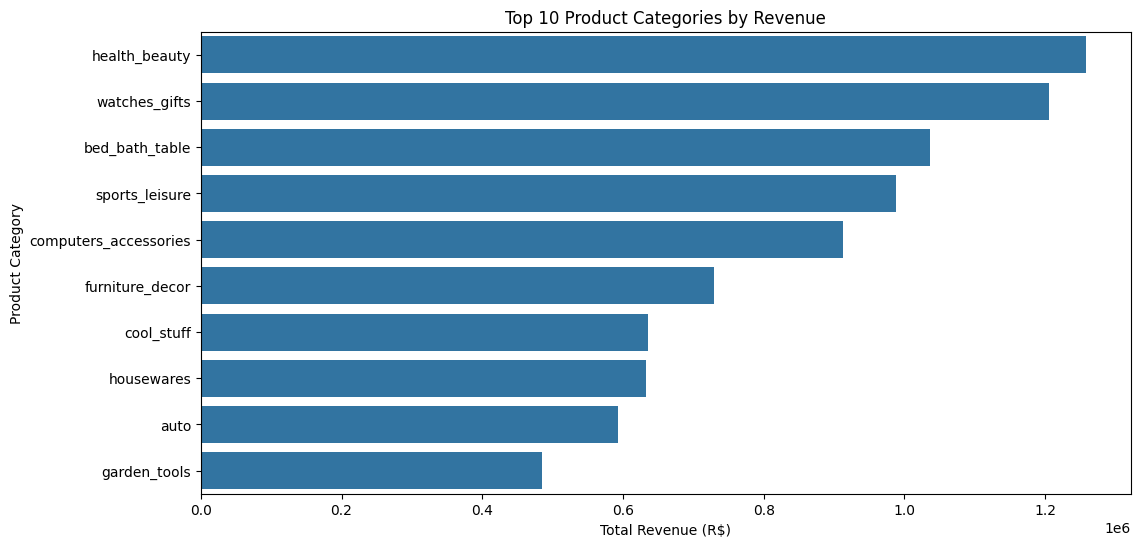

In [108]:
category_revenue = order_items.merge(
    products[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
)

top_category_revenue = (
    category_revenue.groupby('product_category_name_english')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_category_revenue.values, y=top_category_revenue.index)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Total Revenue (R$)')
plt.ylabel('Product Category')
plt.show()

In [109]:
print(top_category_revenue)

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64


In [110]:
category_sales = (
    category_revenue.groupby('product_category_name_english')['order_item_id']
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print(category_sales)

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: order_item_id, dtype: int64


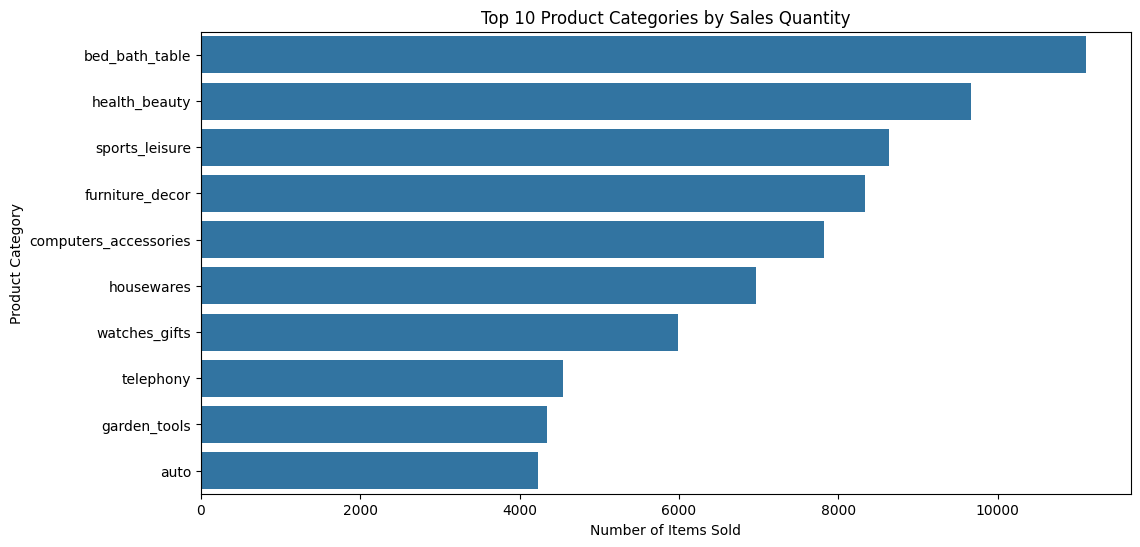

In [111]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title('Top 10 Product Categories by Sales Quantity')
plt.xlabel('Number of Items Sold')
plt.ylabel('Product Category')
plt.show()

In [112]:
master_data = orders.merge(
    customers,
    on='customer_id',
    how='left'
)

master_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_year,order_month,month_name,order_year_month,delivery_time,approval_time,processing_time,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,October,2017-10,8.0,0.178333,56.795833,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,July,2018-07,13.0,30.713889,11.109167,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,August,2018-08,9.0,0.276111,4.910278,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,November,2017-11,13.0,0.298056,89.900000,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,February,2018-02,2.0,1.030556,21.434722,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [113]:
order_items_summary = order_items.groupby('order_id').agg(
    total_items=('order_item_id', 'count'),
    total_revenue=('price', 'sum'),
    total_freight=('freight_value', 'sum')
).reset_index()

order_items_summary.head()

,order_id,total_items,total_revenue,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [114]:
master_data = master_data.merge(
    order_items_summary,
    on='order_id',
    how='left'
)

master_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_year,order_month,...,delivery_time,approval_time,processing_time,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_items,total_revenue,total_freight
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,8.0,0.178333,56.795833,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,13.0,30.713889,11.109167,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,9.0,0.276111,4.910278,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,13.0,0.298056,89.900000,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,2.0,1.030556,21.434722,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,19.90,8.72


In [115]:
payment_summary = payments.groupby('order_id').agg(
    total_payment=('payment_value', 'sum'),
    payment_installments=('payment_installments', 'max')
).reset_index()

payment_summary.head()

,order_id,total_payment,payment_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2
1,00018f77f2f0320c557190d7a144bdd3,259.83,3
2,000229ec398224ef6ca0657da4fc703e,216.87,5
3,00024acbcdf0a6daa1e931b038114c75,25.78,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3


In [116]:
review_summary = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

review_summary.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


## 6. Master Dataset Creation

In [117]:
master_data = master_data.merge(
    review_summary,
    on='order_id',
    how='left'
)

master_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_year,order_month,...,approval_time,processing_time,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_items,total_revenue,total_freight,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,...,0.178333,56.795833,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,...,30.713889,11.109167,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,...,0.276111,4.910278,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,...,0.298056,89.900000,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,45.00,27.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,...,1.030556,21.434722,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,19.90,8.72,5.0


In [133]:
master_data['order_year_month'] = (
    master_data['order_purchase_timestamp'].dt.strftime('%Y-%m')
)

In [134]:
master_data[['order_purchase_timestamp', 'order_year_month']].head()

,order_purchase_timestamp,order_year_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


In [118]:
print("Master Dataset Shape:", master_data.shape)

print("Original Orders Shape:", orders.shape)

print("Duplicate Orders:", master_data['order_id'].duplicated().sum())

Master Dataset Shape: (99441, 23)
Original Orders Shape: (99441, 15)
Duplicate Orders: 0


In [119]:
missing_values = master_data.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

delivery_time                    2965
order_delivered_customer_date    2965
processing_time                  1797
order_delivered_carrier_date     1783
total_freight                     775
total_items                       775
total_revenue                     775
review_score                      768
order_approved_at                 160
approval_time                     160
dtype: int64

In [120]:
master_data[
    master_data['total_items'].isnull()
]['order_status'].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [121]:
master_data['review_score'].isnull().sum()

np.int64(768)

In [122]:
master_data.to_csv(
    "../Dataset/olist_master_data.csv",
    index=False
)

print("Master dataset saved successfully!")

Master dataset saved successfully!


## 7. Key Performance Indicators (KPIs)

In [123]:
total_orders = master_data['order_id'].nunique()

total_sales = master_data['total_revenue'].sum()

average_order_value = total_sales / master_data['order_id'].nunique()

average_rating = master_data['review_score'].mean()

print("Total Orders:", total_orders)
print("Total Sales: R$", round(total_sales, 2))
print("Average Order Value: R$", round(average_order_value, 2))
print("Average Customer Rating:", round(average_rating, 2))

Total Orders: 99441
Total Sales: R$ 13591643.7
Average Order Value: R$ 136.68
Average Customer Rating: 4.09


In [124]:
status_analysis = master_data['order_status'].value_counts().reset_index()

status_analysis.columns = ['Order Status', 'Order Count']

status_analysis['Percentage'] = (
    status_analysis['Order Count'] / total_orders * 100
).round(2)

status_analysis

,Order Status,Order Count,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [125]:
monthly_sales = master_data.groupby('order_year_month')['total_revenue'].sum()

monthly_sales.tail(15)

order_year_month
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
2018-10          0.00
Freq: M, Name: total_revenue, dtype: float64

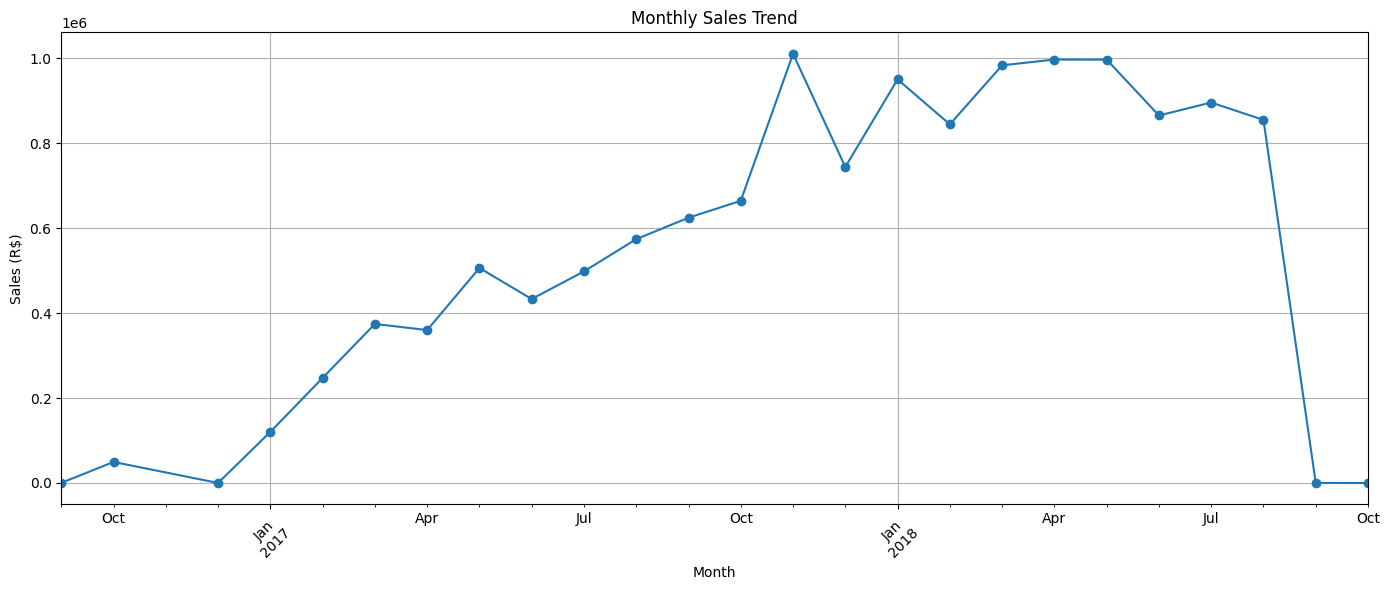

In [126]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales (R$)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("../Visualizations/monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [127]:
top_categories = (
    category_revenue.groupby('product_category_name_english')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_categories

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

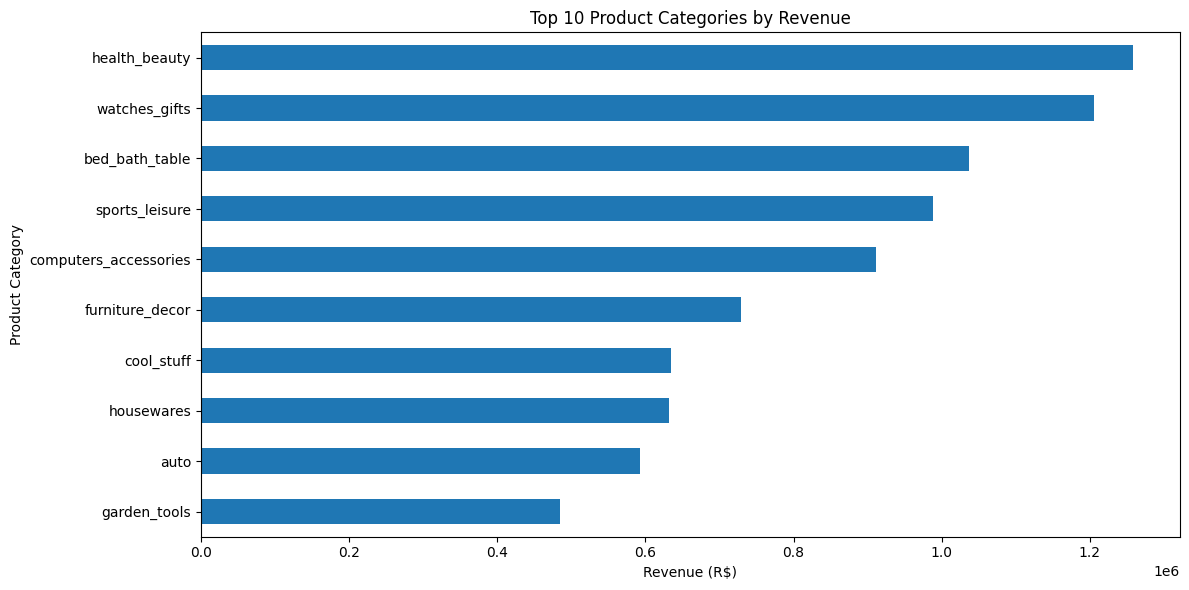

In [128]:
plt.figure(figsize=(12, 6))

top_categories.sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Product Category')
plt.tight_layout()
plt.savefig("../Visualizations/top_10_categories_by_revenue.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [129]:
payment_analysis = payments.groupby('payment_type').agg(
    total_transactions=('payment_type', 'count'),
    total_payment=('payment_value', 'sum')
).sort_values('total_payment', ascending=False)

payment_analysis

,total_transactions,total_payment
payment_type,,
credit_card,76795,12542084.19
boleto,19784,2869361.27
voucher,5775,379436.87
debit_card,1529,217989.79
not_defined,3,0.00


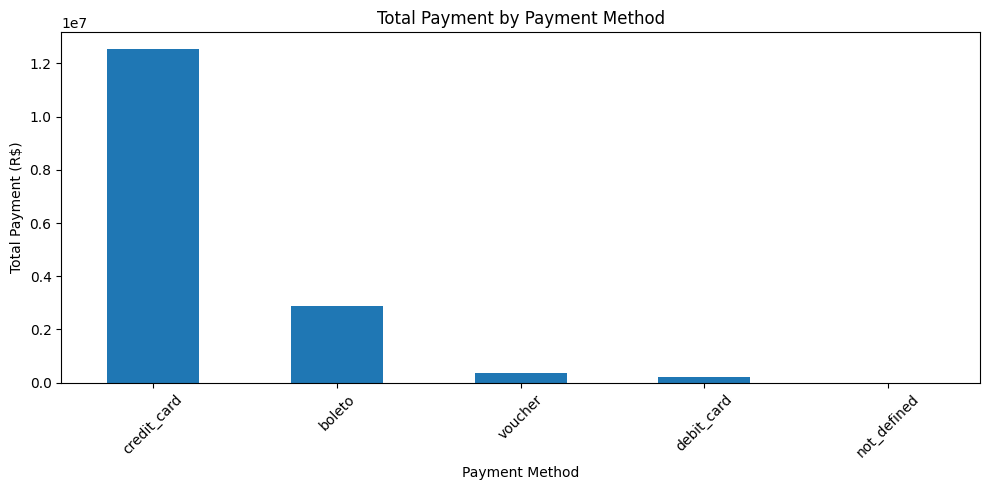

In [130]:
plt.figure(figsize=(10, 5))

payment_analysis['total_payment'].plot(kind='bar')

plt.title('Total Payment by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Payment (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../Visualizations/payment_by_method.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [131]:
print("TOTAL ORDERS:", total_orders)
print("TOTAL SALES: R$", round(total_sales, 2))
print("AVERAGE ORDER VALUE: R$", round(total_sales / order_items['order_id'].nunique(), 2))
print("AVERAGE CUSTOMER RATING:", round(average_rating, 2))
print("AVERAGE DELIVERY TIME:", round(orders['delivery_time'].mean(), 2), "days")

TOTAL ORDERS: 99441
TOTAL SALES: R$ 13591643.7
AVERAGE ORDER VALUE: R$ 137.75
AVERAGE CUSTOMER RATING: 4.09
AVERAGE DELIVERY TIME: 12.09 days


## 8. Business Insights and Recommendations

In [132]:
insights = {
    "Top Revenue Category": top_categories.index[0],
    "Most Popular Payment Method": payment_analysis['total_payment'].idxmax(),
    "Most Common Order Status": master_data['order_status'].mode()[0],
    "Highest Customer Rating": review_delivery.idxmin(),
    "Average Delivery Time": round(orders['delivery_time'].mean(), 2)
}

insights

{'Top Revenue Category': 'health_beauty',
 'Most Popular Payment Method': 'credit_card',
 'Most Common Order Status': 'delivered',
 'Highest Customer Rating': np.int64(5),
 'Average Delivery Time': np.float64(12.09)}

In [136]:
master_data.to_csv("../Dataset/olist_master_data.csv", index=False)

### Business Recommendations

1. **Focus on High-Revenue Categories:** Increase marketing and promotional activities for Health & Beauty and Watches & Gifts.

2. **Improve Delivery Performance:** Reduce delivery delays by improving logistics and monitoring shipping performance.

3. **Encourage Credit Card Payments:** Continue supporting credit card payments while improving other payment options.

4. **Improve Customer Satisfaction:** Investigate low-rated orders and identify delivery-related issues.

5. **Increase Average Order Value:** Introduce product bundles and cross-selling strategies to encourage customers to purchase more items.

## 9. Conclusion

### Conclusion

This project analysed the Olist E-commerce dataset to understand sales performance, customer behaviour, product categories, payment methods, order delivery and customer satisfaction.

Using Python, Pandas, NumPy, Matplotlib and Seaborn, I performed data cleaning, exploratory data analysis, data merging and visualization.

The analysis identified Health & Beauty as the highest revenue-generating category, Credit Card as the leading payment method, and an average customer rating of 4.09 out of 5.

The findings provide useful business insights and recommendations to improve sales, delivery performance and customer satisfaction.